# Instructions for using the Kuva Space hyperspectral airborne collection

## Libraries

Ensure all required packages are installed and imported.

In [1]:
import pystac_client
import matplotlib
import numpy as np
import os
import stackstac
import folium
import pyproj
import PIL

* `pystac_client`, `stackstack`: A Python library for working with STAC catalogs. It enables interaction with STAC services, reading catalog information, and searching for products based on specified parameters.
* `matplotlib`: A Python library for creating charts, plots, and raster visualizations.
* `numpy`: A library for fast numerical and array operations.
* `folium`: Create interactive maps.
* `pyproj`: Transform coordinates between geographic projections.
* `PIL`: Open, edit, and save images.

## S3 Credentials

In order to access the data from CloudFerro's catalog, authentication is required. To facilitate this, you will need to create an account in the Copernicus Data Space Ecosystem (CDSE). You can find the registration link here: https://documentation.dataspace.copernicus.eu/APIs/S3.html.

Once you have created an account, the same URL will redirect you to the section where you can generate your `S3 Credentials`. To do this, simply click the `Add Credential` button. This will allow you to define an expiration date for your credentials.

After selecting the expiration date, you will have successfully created your own S3 credentials. Please make sure to save the secret key at this point, as it will not be displayed again.

Now that you have your S3 credentials, you can use them to connect to the STAC catalog.

The only variables you need to configure are:
* `CDSE_S3_ACCESS_KEY`
* `CDSE_S3_SECRET_KEY`.

In [ ]:
# os.environ["CDSE_S3_ACCESS_KEY"] = "CDSE_S3_ACCESS_KEY" # Replace with your keys!
# os.environ["CDSE_S3_SECRET_KEY"] = "CDSE_S3_SECRET_KEY" # Replace with your keys!

In [3]:
os.environ["GDAL_HTTP_TCP_KEEPALIVE"] = "YES"
os.environ["AWS_S3_ENDPOINT"] = "eodata.dataspace.copernicus.eu"
os.environ["AWS_ACCESS_KEY_ID"] = os.environ.get("CDSE_S3_ACCESS_KEY")
os.environ["AWS_SECRET_ACCESS_KEY"] = os.environ.get("CDSE_S3_SECRET_KEY")
os.environ["AWS_HTTPS"] = "YES"
os.environ["AWS_VIRTUAL_HOSTING"] = "FALSE"

## Connecting to the STAC Catalog

We connect to the Copernicus STAC catalog, available at the endpoint: https://stac.opensearch.dataspace.copernicus.eu/v1.

In [4]:
URL = "https://stac.opensearch.dataspace.copernicus.eu/v1"
cat = pystac_client.Client.open(URL)

## Defining the Area of Interest (AOI)

This is an area which includes Lake Enäjärvi, Finland.

In [5]:
geom = {
        "type": "Polygon",
        "coordinates": [
          [
            [
              24.31972336083831,
              60.37108795996028
            ],
            [
              24.43717882319055,
              60.37108795996028
            ],
            [
              24.43717882319055,
              60.323533680756526
            ],
            [
              24.31972336083831,
              60.323533680756526
            ],
            [
              24.31972336083831,
              60.37108795996028
            ]
          ]
        ]
      }

## Defining Search Parameters

* `max_items`: The maximum number of results to retrieve.
* `collections`: The STAC collection.
* `datetime`: Time range in YYYY-MM-DD/YYYY-MM-DD format.
* `intersects`: The previously defined area of interest.
* `query`: A key-value pair where the key represents a specific property (e.g., eo:cloud_cover), and the value is the condition or comparison being applied.

In [6]:
params = {
    "max_items": 10,
    "collections": "ccm-hyperspectral-ref-vhr",
    "datetime": "2025-08-14/2025-08-15",
    "intersects": geom,
}

## Searching the Catalog

We query the catalog and convert the results into a list of STAC items.

In [7]:
items = list(cat.search(**params).items())
print(f"Items found: {len(items)}")

Items found: 6


In [8]:
stack = stackstac.stack(
    items=items,
    resolution=(10, 10),
    bounds_latlon=(24.3197233608383, 60.323533680756526, 24.43717882319055, 60.37108795996028),
    chunksize=98304,
    epsg=32634,
    gdal_env=stackstac.DEFAULT_GDAL_ENV.updated(
        {
            "GDAL_NUM_THREADS": -1,
            "GDAL_HTTP_UNSAFESSL": "YES",
            "GDAL_HTTP_TCP_KEEPALIVE": "YES",
            "AWS_VIRTUAL_HOSTING": "FALSE",
            "AWS_HTTPS": "YES",
        }
    ),
)

# List available bands

Here we can see all the available bands with their wavelengths.

In [9]:
print("Available wavelengths:")
for idx, band in enumerate(stack.band.values):
    print(f"Band {idx + 1}: {band.split('_')[1]}")

Available wavelengths:
Band 1: 411nm
Band 2: 413nm
Band 3: 416nm
Band 4: 419nm
Band 5: 422nm
Band 6: 425nm
Band 7: 428nm
Band 8: 431nm
Band 9: 434nm
Band 10: 437nm
Band 11: 440nm
Band 12: 443nm
Band 13: 445nm
Band 14: 448nm
Band 15: 451nm
Band 16: 454nm
Band 17: 457nm
Band 18: 460nm
Band 19: 463nm
Band 20: 466nm
Band 21: 469nm
Band 22: 472nm
Band 23: 475nm
Band 24: 477nm
Band 25: 480nm
Band 26: 483nm
Band 27: 486nm
Band 28: 489nm
Band 29: 492nm
Band 30: 495nm
Band 31: 498nm
Band 32: 501nm
Band 33: 504nm
Band 34: 506nm
Band 35: 509nm
Band 36: 512nm
Band 37: 515nm
Band 38: 518nm
Band 39: 521nm
Band 40: 524nm
Band 41: 527nm
Band 42: 530nm
Band 43: 533nm
Band 44: 536nm
Band 45: 538nm
Band 46: 541nm
Band 47: 544nm
Band 48: 547nm
Band 49: 550nm
Band 50: 553nm
Band 51: 556nm
Band 52: 559nm
Band 53: 562nm
Band 54: 565nm
Band 55: 568nm
Band 56: 570nm
Band 57: 573nm
Band 58: 576nm
Band 59: 579nm
Band 60: 582nm
Band 61: 585nm
Band 62: 588nm
Band 63: 591nm
Band 64: 594nm
Band 65: 597nm
Band 66: 60

## NDCI

NDCI (Normalized Difference Chlorophyll Index) estimates chlorophyll-a levels in water using red and red-edge reflectance. Higher values generally indicate more chlorophyll and potentially greater algal activity.
$$
\mathrm{NDCI} = \frac{RED\_EDGE - RED}{RED\_EDGE + RED}
$$

Where:
- `RED_EDGE` is the Red Edge band (b114_739nm).
- `RED` is the Red band (b90_669nm).

In [10]:
red = stack.sel(band="b90_669nm")
rededge = stack.sel(band="b114_739nm")

In [18]:
ndci = (rededge - red) / (rededge + red)
ndci_median = ndci.median(dim="time", skipna=True)

Display NDCI on a map, so we can see algae bloom across the lake.


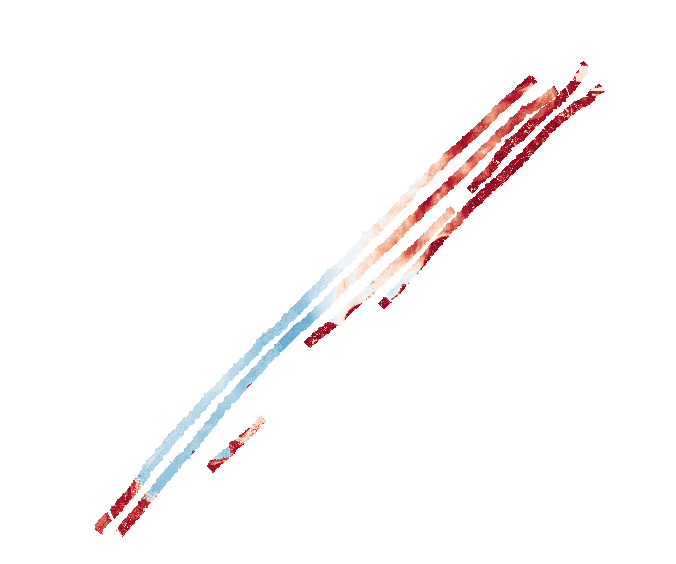

In [21]:
import branca.colormap as bcm
import folium
import numpy as np
from PIL import Image
from matplotlib import colormaps, colors
from pyproj import CRS, Transformer
import warnings

warnings.filterwarnings(
    "ignore",
    message="All-NaN slice encountered",
    category=RuntimeWarning,
)

da = ndci_median.compute()
x, y = da["x"].values.astype(float), da["y"].values.astype(float)
data = da.values

def pixel_edges(coords):
    midpoints = (coords[:-1] + coords[1:]) / 2
    return np.r_[coords[0] - (coords[1] - coords[0]) / 2,
                 midpoints,
                 coords[-1] + (coords[-1] - coords[-2]) / 2]

x_edges, y_edges = pixel_edges(x), pixel_edges(y)

transformer = Transformer.from_crs(
    CRS.from_user_input(da.coords["epsg"].item()),
    "EPSG:4326",
    always_xy=True,
)
west, south, east, north = transformer.transform_bounds(
    x_edges.min(), y_edges.min(), x_edges.max(), y_edges.max()
)
bounds = [[south, west], [north, east]]

vmin, vmax = -1, 1
cmap = colormaps["RdBu_r"]
rgba = cmap(colors.Normalize(vmin, vmax, clip=True)(data), bytes=True)
rgba[~np.isfinite(data)] = (0, 0, 0, 0)

m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=13,
    tiles="OpenStreetMap",
)

folium.raster_layers.ImageOverlay(
    image=Image.fromarray(rgba),
    bounds=bounds,
    opacity=0.8,
    name="NDCI",
).add_to(m)

bcm.LinearColormap(
    [colors.to_hex(cmap(t)) for t in np.linspace(0, 1, 11)],
    vmin=vmin,
    vmax=vmax,
    caption="NDCI",
).add_to(m)

folium.LayerControl().add_to(m)
m